<a href="https://colab.research.google.com/github/CauaMaia/processamento_de_imagens/blob/main/Atividade13_11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/CauaMaia/processamento_de_imagens/blob/main/Atividade13_11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN para classificação de imagens (CIFAR-10)

## 1. Carregando os dados

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

In [2]:
dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Usando:', dispositivo)

Usando: cuda


In [3]:
# hiperparâmetros
epocas = 10
tam_lote = 64
taxa_aprendizado = 0.01

In [4]:
# converte para tensor e normaliza cada canal para o intervalo [-1, 1]
transformacao = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [5]:
dados_treino = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transformacao)
dados_teste = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transformacao)

carregador_treino = torch.utils.data.DataLoader(dados_treino, batch_size=tam_lote, shuffle=True)
carregador_teste = torch.utils.data.DataLoader(dados_teste, batch_size=tam_lote, shuffle=False)

print('Imagens de treino:', len(dados_treino))
print('Imagens de teste:', len(dados_teste))

100%|██████████| 170M/170M [00:40<00:00, 4.26MB/s]


Imagens de treino: 50000
Imagens de teste: 10000


In [6]:
classes = ['avião', 'carro', 'pássaro', 'gato', 'cervo',
           'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']


def desnormalizar(img):
    # volta de [-1, 1] para [0, 1] e de (C, H, W) para (H, W, C) para o imshow
    img = img.numpy() * 0.5 + 0.5
    return np.transpose(img, (1, 2, 0))


def mostrar_lote(imagens, rotulos, n=8):
    plt.figure(figsize=(2*n, 2.5))
    for i in range(n):
        plt.subplot(1, n, i+1)
        plt.imshow(desnormalizar(imagens[i]))
        plt.title(classes[rotulos[i]])
        plt.axis('off')
    plt.show()

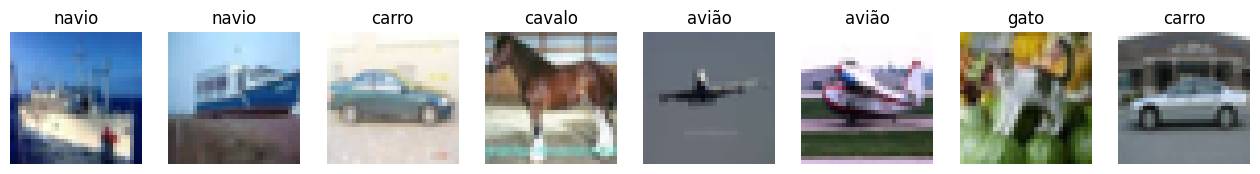

In [7]:
# algumas imagens do conjunto de treino
imagens, rotulos = next(iter(carregador_treino))
mostrar_lote(imagens, rotulos)

## 2. Definindo a CNN

In [8]:
class RedeConv(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)       # 3x32x32 -> 6x28x28
        self.conv2 = nn.Conv2d(6, 16, 5)      # 6x14x14 -> 16x10x10
        self.pool = nn.MaxPool2d(2, 2)        # reduz altura e largura pela metade
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)          # 10 classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # -> 6x14x14
        x = self.pool(F.relu(self.conv2(x)))  # -> 16x5x5
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


modelo = RedeConv().to(dispositivo)
print(modelo)

RedeConv(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


## 3. Treinamento

In [9]:
funcao_perda = nn.CrossEntropyLoss()
otimizador = torch.optim.SGD(modelo.parameters(), lr=taxa_aprendizado, momentum=0.9)

In [10]:
historico_perda = []

for epoca in range(epocas):
    modelo.train()
    perda_total = 0.0

    for imagens, rotulos in carregador_treino:
        imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)

        saidas = modelo(imagens)
        perda = funcao_perda(saidas, rotulos)

        otimizador.zero_grad()
        perda.backward()
        otimizador.step()

        perda_total += perda.item()

    perda_media = perda_total / len(carregador_treino)
    historico_perda.append(perda_media)
    print(f'Época {epoca+1:2d}/{epocas} - perda: {perda_media:.3f}')

Época  1/10 - perda: 1.832
Época  2/10 - perda: 1.393
Época  3/10 - perda: 1.243
Época  4/10 - perda: 1.140
Época  5/10 - perda: 1.065
Época  6/10 - perda: 1.000
Época  7/10 - perda: 0.942
Época  8/10 - perda: 0.896
Época  9/10 - perda: 0.854
Época 10/10 - perda: 0.824


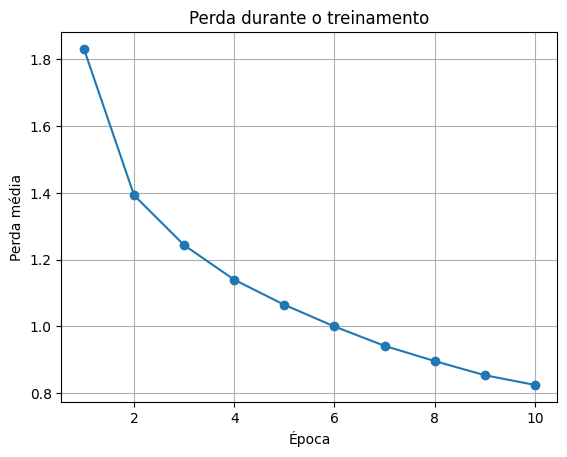

In [11]:
plt.plot(range(1, epocas+1), historico_perda, marker='o')
plt.title('Perda durante o treinamento')
plt.xlabel('Época')
plt.ylabel('Perda média')
plt.grid(True)
plt.show()

## 4. Avaliação no conjunto de teste

In [12]:
modelo.eval()
acertos, total = 0, 0
acertos_classe = [0] * 10
total_classe = [0] * 10

with torch.no_grad():
    for imagens, rotulos in carregador_teste:
        imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)
        _, previstos = torch.max(modelo(imagens), 1)

        total += rotulos.size(0)
        acertos += (previstos == rotulos).sum().item()

        for real, prev in zip(rotulos.tolist(), previstos.tolist()):
            total_classe[real] += 1
            acertos_classe[real] += int(real == prev)

print(f'Acurácia geral: {100 * acertos / total:.1f}%\n')
for i, nome_classe in enumerate(classes):
    print(f'{nome_classe:>9}: {100 * acertos_classe[i] / total_classe[i]:.1f}%')

Acurácia geral: 64.1%

    avião: 69.6%
    carro: 76.6%
  pássaro: 45.7%
     gato: 58.4%
    cervo: 44.4%
 cachorro: 51.3%
     sapo: 80.9%
   cavalo: 70.7%
    navio: 67.0%
 caminhão: 76.2%


## 5. Testando com uma imagem própria

A imagem enviada é recortada e reduzida para 32x32, que é o tamanho que a rede recebe.

Saving carro-vermelho-de-desenho-animado_601658-2609.avif to carro-vermelho-de-desenho-animado_601658-2609.avif


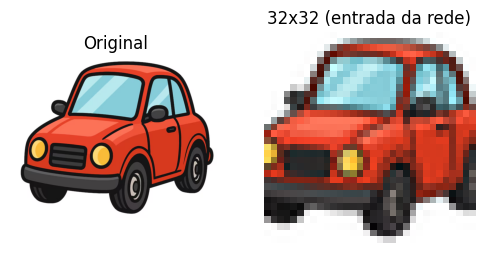

Top 3 previsões:
    carro: 75.1%
 caminhão: 24.9%
 cachorro: 0.0%


In [19]:
from google.colab import files
from PIL import Image, ImageOps

enviados = files.upload()
arquivo = list(enviados.keys())[0]

img = Image.open(arquivo).convert('RGB')
img_32 = ImageOps.fit(img, (32, 32), method=Image.LANCZOS)

entrada = transformacao(img_32).unsqueeze(0).to(dispositivo)

modelo.eval()
with torch.no_grad():
    probabilidades = F.softmax(modelo(entrada), dim=1)[0]

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_32)
plt.title('32x32 (entrada da rede)')
plt.axis('off')
plt.show()

melhores = torch.topk(probabilidades, 3)
print('Top 3 previsões:')
for p, i in zip(melhores.values, melhores.indices):
    print(f'{classes[i]:>9}: {100 * p:.1f}%')